In [1]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd

file_path = '/content/drive/MyDrive/time_series/nepal_fao_rice_production_1961_2024.csv'
df = pd.read_csv(file_path)
df.head()

Mounted at /content/drive


,Year,Rice_Production_tonnes
0,1961,2108000
1,1962,2108000
2,1963,2109000
3,1964,2201000
4,1965,2207000


### Step 2: Time Series Analysis, Decomposition, and Autocorrelations
We will start by plotting the raw series, performing decomposition, and plotting the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF).

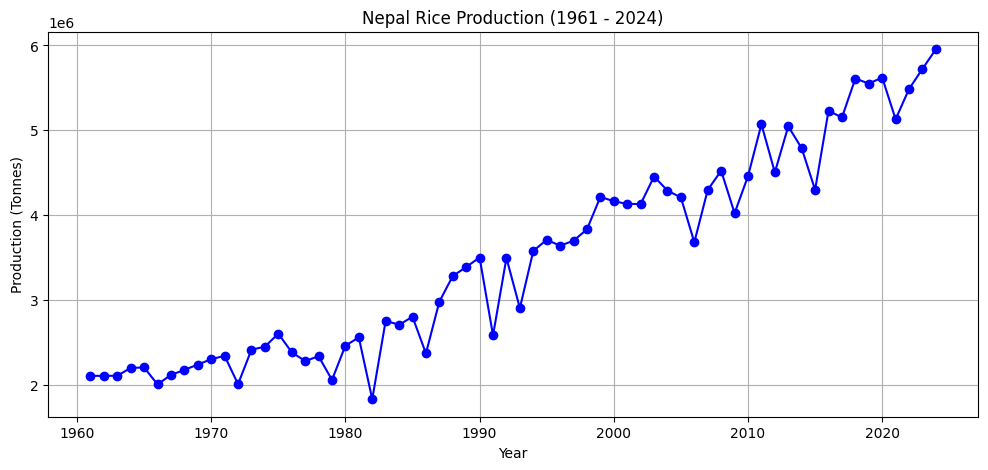

In [2]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Ensure Year is the index and sorted
df_sorted = df.copy().sort_values('Year')
df_sorted.set_index('Year', inplace=True)

# Plot original time series
plt.figure(figsize=(12, 5))
plt.plot(df_sorted.index, df_sorted['Rice_Production_tonnes'], marker='o', color='b')
plt.title('Nepal Rice Production (1961 - 2024)')
plt.xlabel('Year')
plt.ylabel('Production (Tonnes)')
plt.grid(True)
plt.show()

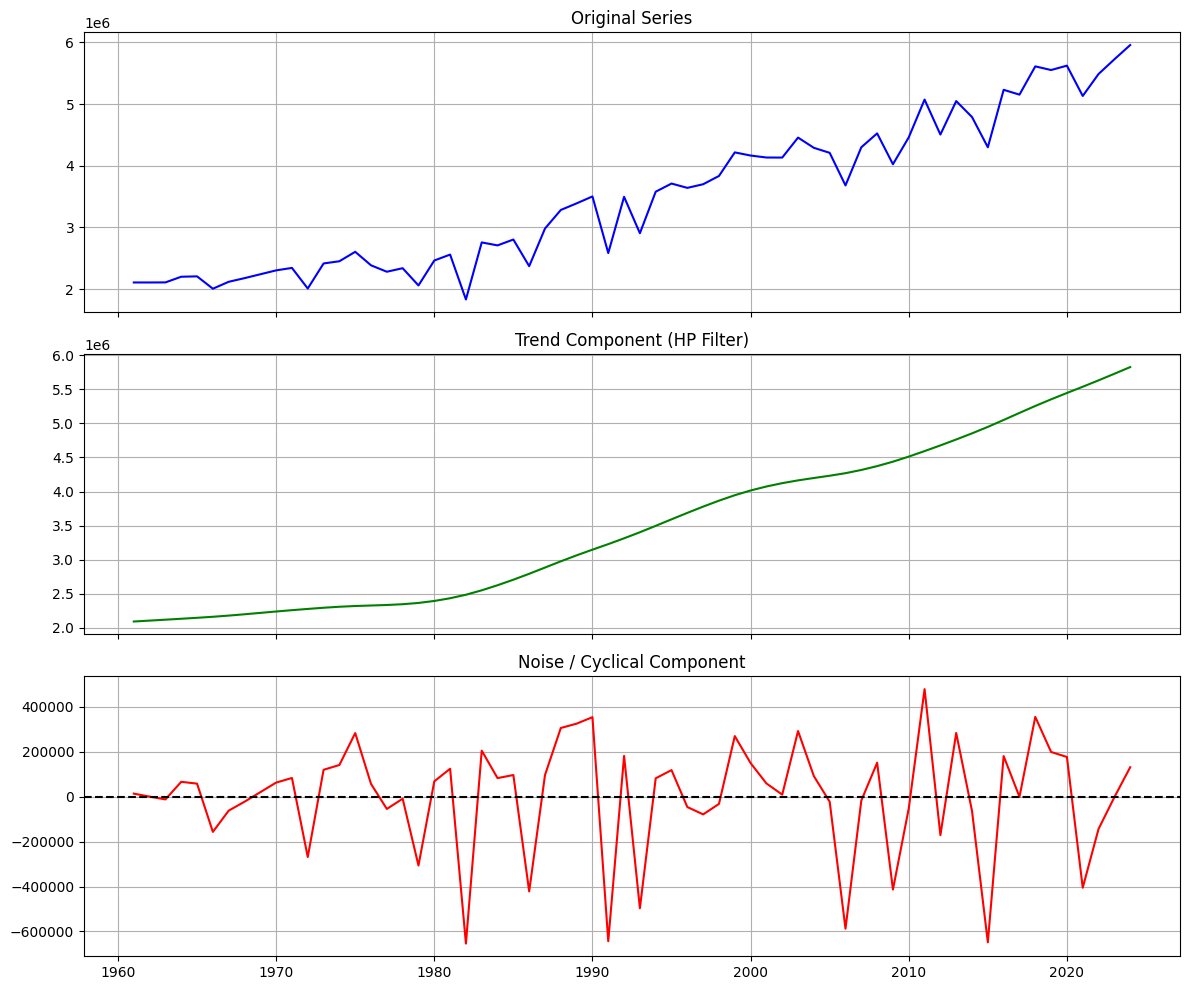

In [3]:
# Since this is annual data, a standard seasonal decomposition with a short period (e.g., no clear seasonality within years) might not be directly applicable.
# However, we can use a Hodrick-Prescott (HP) filter to decompose the series into a trend and noise component,
# or apply seasonal_decompose with an assumed multi-year cycle (e.g., period=5 or 10 if there are cyclical patterns).
# Let's use HP filter for robust trend-cycle decomposition of annual data.

cycle, trend = sm.tsa.filters.hpfilter(df_sorted['Rice_Production_tonnes'], lamb=100)

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Original Series
axes[0].plot(df_sorted.index, df_sorted['Rice_Production_tonnes'], label='Original', color='blue')
axes[0].set_title('Original Series')
axes[0].grid(True)

# Trend Component
axes[1].plot(df_sorted.index, trend, label='Trend', color='green')
axes[1].set_title('Trend Component (HP Filter)')
axes[1].grid(True)

# Residual / Noise Component
axes[2].plot(df_sorted.index, cycle, label='Noise/Cycle', color='red')
axes[2].axhline(0, color='black', linestyle='--')
axes[2].set_title('Noise / Cyclical Component')
axes[2].grid(True)

plt.tight_layout()
plt.show()

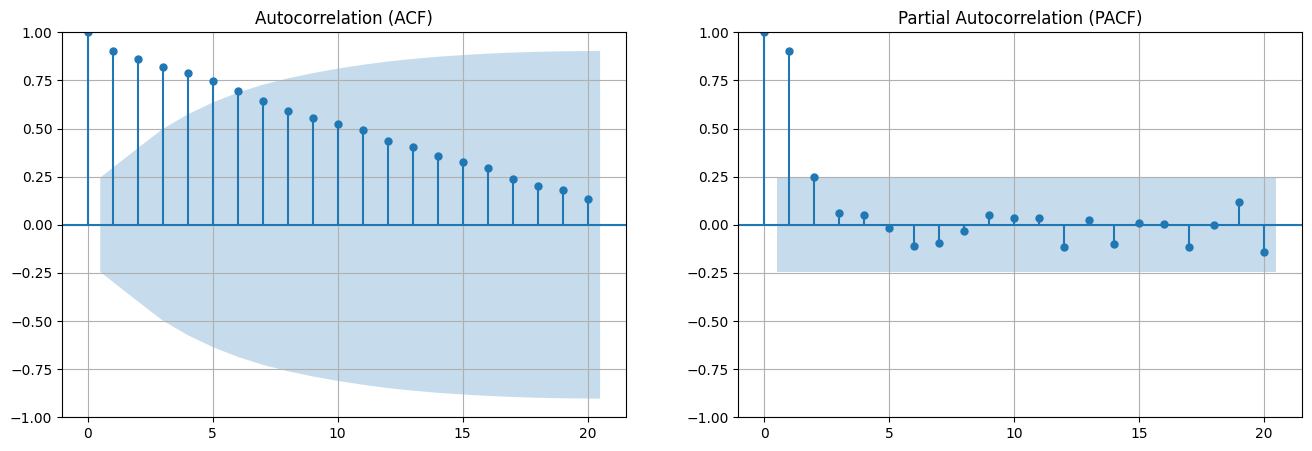

In [4]:
# Autocorrelation & Partial Autocorrelation Analysis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

plot_acf(df_sorted['Rice_Production_tonnes'], lags=20, ax=ax1)
ax1.set_title('Autocorrelation (ACF)')
ax1.grid(True)

plot_pacf(df_sorted['Rice_Production_tonnes'], lags=20, ax=ax2, method='ywm')
ax2.set_title('Partial Autocorrelation (PACF)')
ax2.grid(True)

plt.show()

### Step 3: Chronological Train-Validation-Test Splitting
We will split the time-series dataset sequentially. Since we have 64 observations (1961 to 2024):
- **Train Set**: 1961 to 2010 (approx. 78% of data, 50 years)
- **Validation Set**: 2011 to 2017 (approx. 11% of data, 7 years)
- **Test Set**: 2018 to 2024 (approx. 11% of data, 7 years)

In [5]:
# Resetting index for easy splitting by row counts
df_split = df_sorted.reset_index()

train_idx = int(len(df_split) * 0.78)
val_idx = int(len(df_split) * 0.89)

train_df = df_split.iloc[:train_idx]
val_df = df_split.iloc[train_idx:val_idx]
test_df = df_split.iloc[val_idx:]

print(f"Train Range: {train_df['Year'].min()} - {train_df['Year'].max()} (Size: {len(train_df)})")
print(f"Validation Range: {val_df['Year'].min()} - {val_df['Year'].max()} (Size: {len(val_df)})")
print(f"Test Range: {test_df['Year'].min()} - {test_df['Year'].max()} (Size: {len(test_df)})")

Train Range: 1961 - 2009 (Size: 49)
Validation Range: 2010 - 2016 (Size: 7)
Test Range: 2017 - 2024 (Size: 8)


## Tasks, Part 2: Classical (Linear) Models
We will evaluate each model using the designated training, validation, and test splits. For each model, we will compute and report:
* **RMSE** (Root Mean Squared Error)
* **MAE** (Mean Absolute Error)
* **MAPE** (Mean Absolute Percentage Error)
* **R²** (R-squared)

In [6]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA

def calculate_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, mape, r2

def plot_predictions(y_true, y_pred, years, title):
    plt.figure(figsize=(10, 5))
    plt.plot(years, y_true, label='Actual', marker='o', color='blue')
    plt.plot(years, y_pred, label='Predicted', marker='x', linestyle='--', color='red')
    plt.title(title)
    plt.xlabel('Year')
    plt.ylabel('Production (Tonnes)')
    plt.legend()
    plt.grid(True)
    plt.show()

### 4. Moving Average MA(q) Model

**How is $q$ decided?**
The order $q$ of an MA process is typically determined by examining the Autocorrelation Function (ACF) plot. For a stationary process, the ACF cuts off and becomes non-significant after lag $q$. However, since our raw series is highly non-stationary, the raw ACF does not cut off. For demonstration, we will train an `ARIMA(0, 0, q)` model. Let's fix $q = 2$ for the moving average component on the raw series.

MA(2) Test Set Evaluation:
RMSE: 1066739.08
MAE: 1040269.33
MAPE: 18.80%
R²: -15.9099


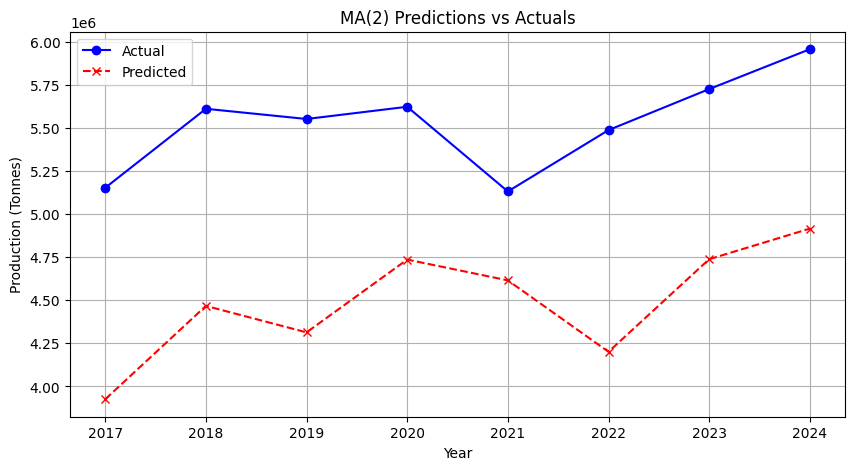

In [7]:
# We will fit a baseline MA(2) model on the levels using ARIMA(0, 0, 2)
q = 2
ma_model = ARIMA(train_df['Rice_Production_tonnes'], order=(0, 0, q))
ma_results = ma_model.fit()

# We perform one-step-ahead forecasts on the test set
# Since it's a dynamic or rolling forecast, we can iteratively append test data to update the model's history
history = list(train_df['Rice_Production_tonnes'].values) + list(val_df['Rice_Production_tonnes'].values)
test_predictions_ma = []

for i in range(len(test_df)):
    temp_model = ARIMA(history, order=(0, 0, q))
    temp_results = temp_model.fit()
    pred = temp_results.forecast(steps=1)[0]
    test_predictions_ma.append(pred)
    history.append(test_df['Rice_Production_tonnes'].iloc[i])

rmse, mae, mape, r2 = calculate_metrics(test_df['Rice_Production_tonnes'].values, test_predictions_ma)
print(f"MA({q}) Test Set Evaluation:")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"MAPE: {mape:.2f}%")
print(f"R²: {r2:.4f}")

plot_predictions(test_df['Rice_Production_tonnes'].values, test_predictions_ma, test_df['Year'].values, f"MA({q}) Predictions vs Actuals")

### 5. Autoregressive AR(p) Model

**How is $p$ decided?**
The order $p$ of an AR process is typically determined by examining the Partial Autocorrelation Function (PACF) plot. In a stationary AR(p) process, the PACF cuts off and falls within the significance bounds after lag $p$. In our PACF plot of the raw series, there is a strong significant spike at lag 1, indicating that $p=1$ is a suitable parameter selection.

AR(1) Test Set Evaluation:
RMSE: 341488.41
MAE: 293008.83
MAPE: 5.28%
R²: -0.7329


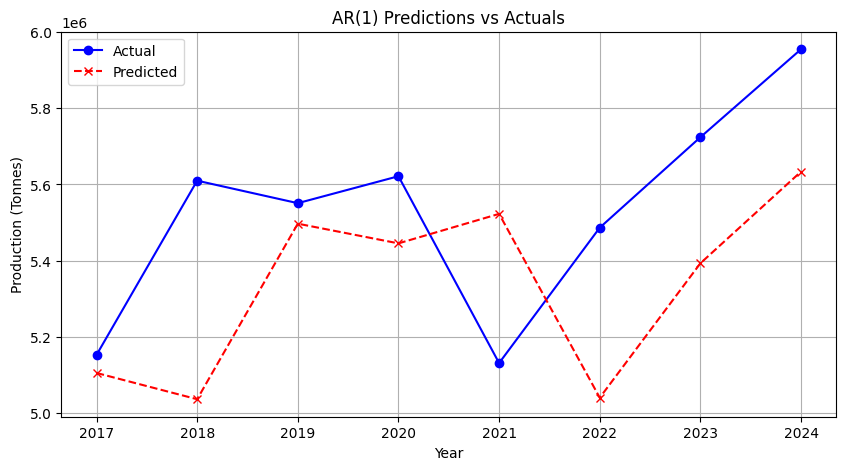

In [8]:
# We will fit an AR(1) model using ARIMA(1, 0, 0)
p = 1
ar_model = ARIMA(train_df['Rice_Production_tonnes'], order=(p, 0, 0))
ar_results = ar_model.fit()

history = list(train_df['Rice_Production_tonnes'].values) + list(val_df['Rice_Production_tonnes'].values)
test_predictions_ar = []

for i in range(len(test_df)):
    temp_model = ARIMA(history, order=(p, 0, 0))
    temp_results = temp_model.fit()
    pred = temp_results.forecast(steps=1)[0]
    test_predictions_ar.append(pred)
    history.append(test_df['Rice_Production_tonnes'].iloc[i])

rmse, mae, mape, r2 = calculate_metrics(test_df['Rice_Production_tonnes'].values, test_predictions_ar)
print(f"AR({p}) Test Set Evaluation:")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"MAPE: {mape:.2f}%")
print(f"R²: {r2:.4f}")

plot_predictions(test_df['Rice_Production_tonnes'].values, test_predictions_ar, test_df['Year'].values, f"AR({p}) Predictions vs Actuals")

### 6 & 7. Stationarity Check and Differencing
We will use the **Augmented Dickey-Fuller (ADF) test** to formally check for stationarity.

In [9]:
from statsmodels.tsa.stattools import adfuller

def check_stationarity(timeseries):
    result = adfuller(timeseries)
    print('ADF Statistic:', result[0])
    print('p-value:', result[1])
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value}')
    if result[1] <= 0.05:
        print("Conclusion: The series is Stationary (Reject H0)")
    else:
        print("Conclusion: The series is Non-Stationary (Fail to reject H0)")

print("--- Raw Series Stationarity Test ---")
check_stationarity(df_sorted['Rice_Production_tonnes'])

--- Raw Series Stationarity Test ---
ADF Statistic: 1.1026086399754464
p-value: 0.9952388248622258
Critical Values:
	1%: -3.5463945337644063
	5%: -2.911939409384601
	10%: -2.5936515282964665
Conclusion: The series is Non-Stationary (Fail to reject H0)


/tmp/ipykernel_657/3345161466.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(timeseries)


Since the raw series is non-stationary, we will apply **First-Order Differencing** ($d=1$) to stabilize the mean and check stationarity again.

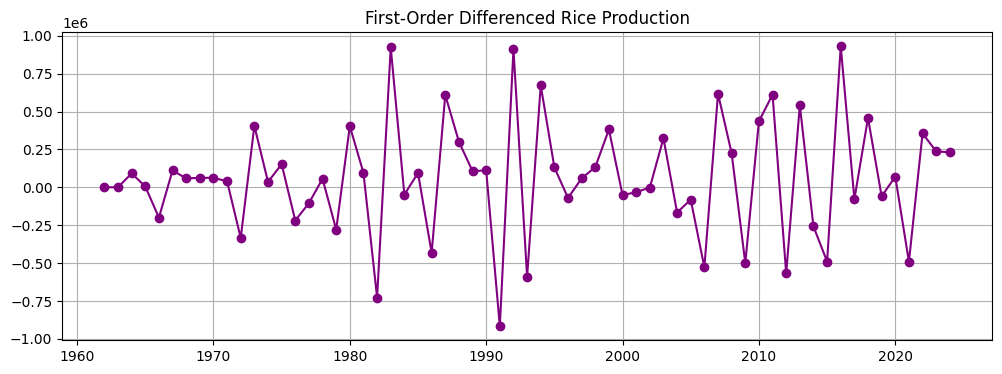

--- Differenced Series Stationarity Test ---
ADF Statistic: -6.063781165600569
p-value: 1.195198136306124e-07
Critical Values:
	1%: -3.5463945337644063
	5%: -2.911939409384601
	10%: -2.5936515282964665
Conclusion: The series is Stationary (Reject H0)


/tmp/ipykernel_657/3345161466.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(timeseries)


In [10]:
df_diff = df_sorted['Rice_Production_tonnes'].diff().dropna()

plt.figure(figsize=(12, 4))
plt.plot(df_diff.index, df_diff, marker='o', color='purple')
plt.title('First-Order Differenced Rice Production')
plt.grid(True)
plt.show()

print("--- Differenced Series Stationarity Test ---")
check_stationarity(df_diff)

### 8. ARIMA(p, d, q) Model
With the series becoming stationary after 1st differencing, we set $d=1$. Combining this with our previous observations ($p=1, q=1$), we will train and evaluate an **ARIMA(1, 1, 1)** model.

ARIMA(1, 1, 1) Test Set Evaluation:
RMSE: 324853.41
MAE: 290983.55
MAPE: 5.28%
R²: -0.5682


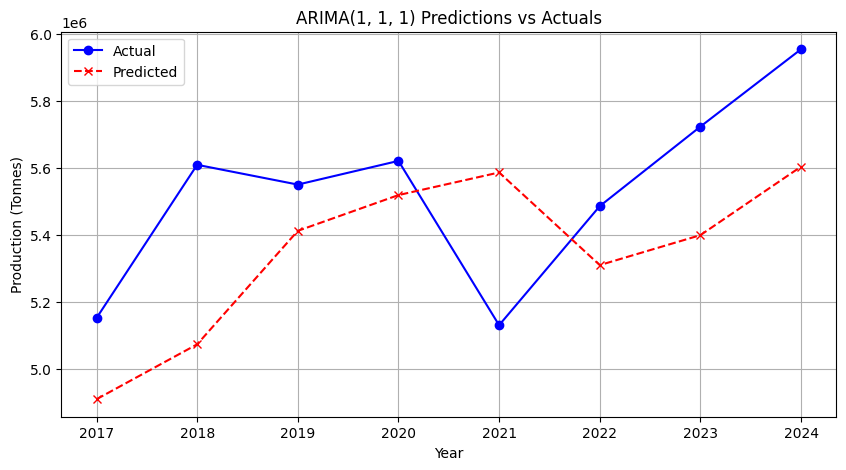

In [11]:
arima_order = (1, 1, 1)

history = list(train_df['Rice_Production_tonnes'].values) + list(val_df['Rice_Production_tonnes'].values)
test_predictions_arima = []

for i in range(len(test_df)):
    temp_model = ARIMA(history, order=arima_order)
    temp_results = temp_model.fit()
    pred = temp_results.forecast(steps=1)[0]
    test_predictions_arima.append(pred)
    history.append(test_df['Rice_Production_tonnes'].iloc[i])

rmse, mae, mape, r2 = calculate_metrics(test_df['Rice_Production_tonnes'].values, test_predictions_arima)
print(f"ARIMA{arima_order} Test Set Evaluation:")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"MAPE: {mape:.2f}%")
print(f"R²: {r2:.4f}")

plot_predictions(test_df['Rice_Production_tonnes'].values, test_predictions_arima, test_df['Year'].values, f"ARIMA{arima_order} Predictions vs Actuals")

## Tasks, Part 3: Neural Network Models
To capture non-linear relationships, we will train and evaluate Deep Learning models (RNN and LSTM) using PyTorch.

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import MinMaxScaler

# Prepare data scaling
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_df[['Rice_Production_tonnes']])
val_scaled = scaler.transform(val_df[['Rice_Production_tonnes']])
test_scaled = scaler.transform(test_df[['Rice_Production_tonnes']])

# Function to create sliding window dataset
def create_sequences(data, lag):
    X, y = [], []
    for i in range(len(data) - lag):
        X.append(data[i:(i + lag)])
        y.append(data[i + lag])
    return np.array(X), np.array(y)

# Define lag size (hyperparameter)
lag_size = 3

X_train, y_train = create_sequences(train_scaled, lag_size)
# Combine train and val dynamically for iterative test evaluation matching classical rolling validation
history_scaled = list(train_scaled.flatten()) + list(val_scaled.flatten())

### 10. Recurrent Neural Network (RNN) Model

Simple RNN Test Set Evaluation:
RMSE: 636675.24
MAE: 584936.03
MAPE: 10.43%
R²: -5.0236


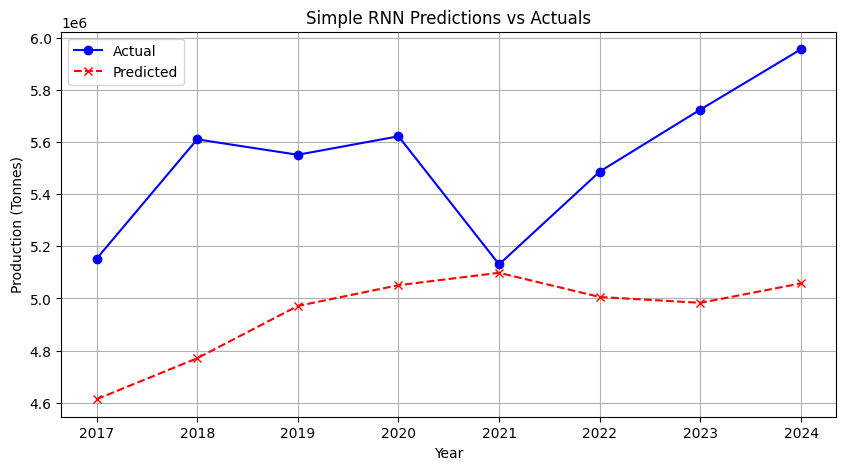

In [13]:
class SimpleRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=16, num_layers=1, output_size=1):
        super(SimpleRNN, self).__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.fc(out[:, -1, :])
        return out

# Convert to PyTorch tensors
X_train_t = torch.FloatTensor(X_train).view(-1, lag_size, 1)
y_train_t = torch.FloatTensor(y_train)

rnn_model = SimpleRNN(hidden_size=32, num_layers=1)
criterion = nn.MSELoss()
optimizer = optim.Adam(rnn_model.parameters(), lr=0.01)

# Training
rnn_model.train()
for epoch in range(150):
    optimizer.zero_grad()
    outputs = rnn_model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

# One-step-ahead rolling forecasting on Test set
rnn_model.eval()
test_predictions_rnn_scaled = []
temp_history = list(history_scaled)

with torch.no_grad():
    for i in range(len(test_scaled)):
        seq = np.array(temp_history[-lag_size:]).reshape(1, lag_size, 1)
        seq_t = torch.FloatTensor(seq)
        pred = rnn_model(seq_t).item()
        test_predictions_rnn_scaled.append(pred)
        temp_history.append(test_scaled[i][0])

test_predictions_rnn = scaler.inverse_transform(np.array(test_predictions_rnn_scaled).reshape(-1, 1)).flatten()

rmse, mae, mape, r2 = calculate_metrics(test_df['Rice_Production_tonnes'].values, test_predictions_rnn)
print("Simple RNN Test Set Evaluation:")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"MAPE: {mape:.2f}%")
print(f"R²: {r2:.4f}")

plot_predictions(test_df['Rice_Production_tonnes'].values, test_predictions_rnn, test_df['Year'].values, "Simple RNN Predictions vs Actuals")

### 11. Long Short-Term Memory (LSTM) Model

LSTM Test Set Evaluation:
RMSE: 779707.97
MAE: 738410.73
MAPE: 13.19%
R²: -8.0342


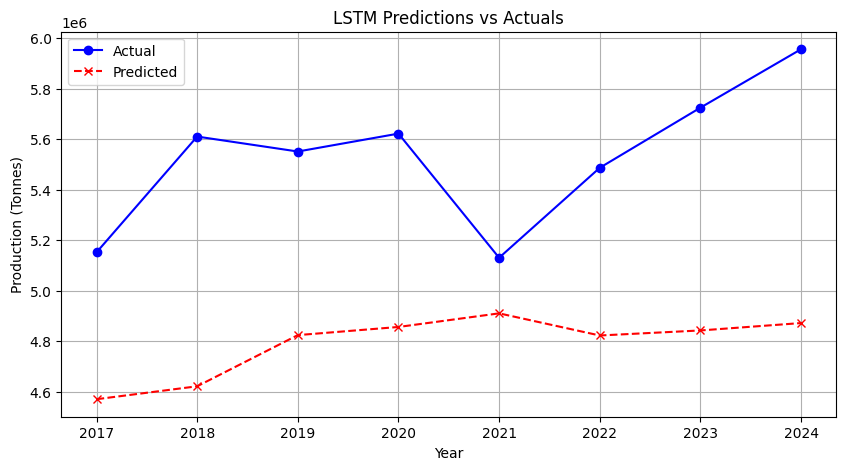

In [14]:
class SimpleLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=16, num_layers=1, output_size=1):
        super(SimpleLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

lstm_model = SimpleLSTM(hidden_size=32, num_layers=1)
optimizer = optim.Adam(lstm_model.parameters(), lr=0.01)

# Training
lstm_model.train()
for epoch in range(150):
    optimizer.zero_grad()
    outputs = lstm_model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

# One-step-ahead rolling forecasting on Test set
lstm_model.eval()
test_predictions_lstm_scaled = []
temp_history = list(history_scaled)

with torch.no_grad():
    for i in range(len(test_scaled)):
        seq = np.array(temp_history[-lag_size:]).reshape(1, lag_size, 1)
        seq_t = torch.FloatTensor(seq)
        pred = lstm_model(seq_t).item()
        test_predictions_lstm_scaled.append(pred)
        temp_history.append(test_scaled[i][0])

test_predictions_lstm = scaler.inverse_transform(np.array(test_predictions_lstm_scaled).reshape(-1, 1)).flatten()

rmse, mae, mape, r2 = calculate_metrics(test_df['Rice_Production_tonnes'].values, test_predictions_lstm)
print("LSTM Test Set Evaluation:")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"MAPE: {mape:.2f}%")
print(f"R²: {r2:.4f}")

plot_predictions(test_df['Rice_Production_tonnes'].values, test_predictions_lstm, test_df['Year'].values, "LSTM Predictions vs Actuals")

### 12. Forecast to Action: The Real-World Decision Framework
In agricultural management, point forecasts (e.g., predicting exactly 5.5 million tonnes of rice) are insufficient because under-preparing and over-preparing both carry heavy financial and societal costs.

**The Decision Context:**
Nepal's Ministry of Agriculture and Land Management must decide on the quantity of grain to import or release from emergency reserves to secure national food safety.
* **Action 1 (Under-forecasting / Under-preparing):** If actual production falls far below the forecast and no action was taken, severe local food deficits, price spikes, and reliance on emergency market-price imports occur.
* **Action 2 (Over-forecasting / Over-preparing):** If we over-import or lock up too much capital in redundant food storage reserves, we incur high holding costs, potential grain spoilage, and wasted public funds.

By converting our point forecasts into **probabilistic forecasts (prediction intervals)**, we can plan for the worst-case scenario (e.g., the 2.5% quantile of national yield) to guarantee food security with high confidence (e.g., 97.5% reliability).

In [15]:
class QuantileLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=16, num_layers=1, output_size=1):
        super(QuantileLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

def pinball_loss(y_pred, y_true, quantile):
    error = y_true - y_pred
    loss = torch.max((quantile - 1) * error, quantile * error)
    return torch.mean(loss)

# Train model helper for a specific quantile
def train_quantile_model(quantile, epochs=250, lr=0.01):
    model = QuantileLSTM(hidden_size=32, num_layers=1)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        outputs = model(X_train_t)
        loss = pinball_loss(outputs, y_train_t, quantile)
        loss.backward()
        optimizer.step()
    return model

# Train 2.5% and 97.5% quantile LSTMs
print("Training 2.5% quantile LSTM model...")
model_q_lower = train_quantile_model(0.025)
print("Training 97.5% quantile LSTM model...")
model_q_upper = train_quantile_model(0.975)

# Generate rolling interval forecasts on test set
model_q_lower.eval()
model_q_upper.eval()
test_preds_lower_scaled = []
test_preds_upper_scaled = []
temp_history = list(history_scaled)

with torch.no_grad():
    for i in range(len(test_scaled)):
        seq = np.array(temp_history[-lag_size:]).reshape(1, lag_size, 1)
        seq_t = torch.FloatTensor(seq)
        pred_lower = model_q_lower(seq_t).item()
        pred_upper = model_q_upper(seq_t).item()

        test_preds_lower_scaled.append(pred_lower)
        test_preds_upper_scaled.append(pred_upper)
        temp_history.append(test_scaled[i][0])

test_preds_lower = scaler.inverse_transform(np.array(test_preds_lower_scaled).reshape(-1, 1)).flatten()
test_preds_upper = scaler.inverse_transform(np.array(test_preds_upper_scaled).reshape(-1, 1)).flatten()

# Ensure lower bounds do not cross upper bounds due to training stochasticity
for i in range(len(test_preds_lower)):
    if test_preds_lower[i] > test_preds_upper[i]:
        test_preds_lower[i], test_preds_upper[i] = test_preds_upper[i], test_preds_lower[i]


Training 2.5% quantile LSTM model...
Training 97.5% quantile LSTM model...


--- Probabilistic Interval Evaluation (95% Confidence) ---
Prediction Interval Coverage Probability (PICP): 12.50%
Mean Prediction Interval Width (MPIW): 1291176.08 Tonnes


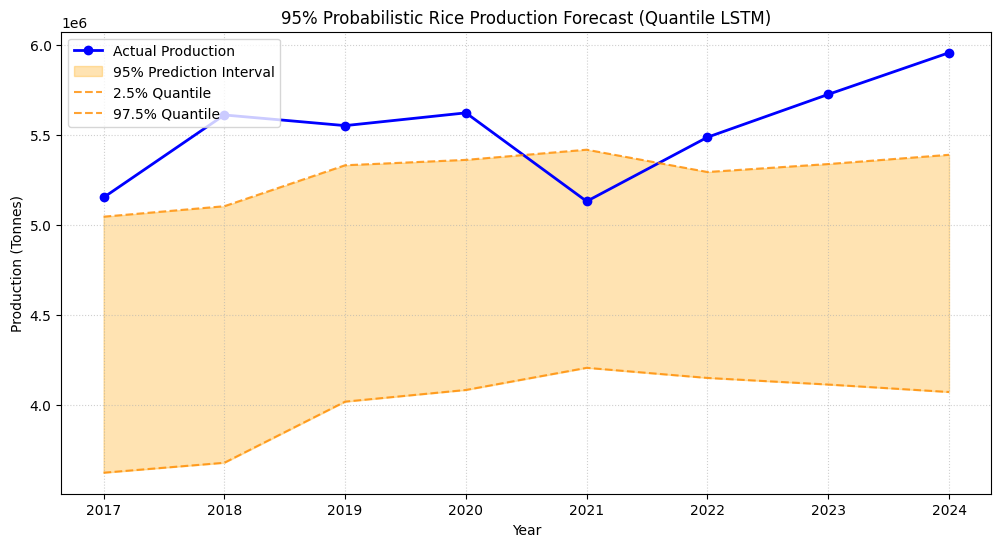

In [16]:
# 13. Evaluate Interval Metrics: PICP and MPIW
y_test_actual = test_df['Rice_Production_tonnes'].values

# Prediction Interval Coverage Probability (PICP)
in_bounds = (y_test_actual >= test_preds_lower) & (y_test_actual <= test_preds_upper)
picp = np.mean(in_bounds) * 100

# Mean Prediction Interval Width (MPIW)
mpiw = np.mean(test_preds_upper - test_preds_lower)

print("--- Probabilistic Interval Evaluation (95% Confidence) ---")
print(f"Prediction Interval Coverage Probability (PICP): {picp:.2f}%")
print(f"Mean Prediction Interval Width (MPIW): {mpiw:.2f} Tonnes")

# Plot the interval forecast against actuals
plt.figure(figsize=(12, 6))
plt.plot(test_df['Year'], y_test_actual, label='Actual Production', marker='o', color='blue', linewidth=2)
plt.fill_between(test_df['Year'], test_preds_lower, test_preds_upper, color='orange', alpha=0.3, label='95% Prediction Interval')
plt.plot(test_df['Year'], test_preds_lower, linestyle='--', color='darkorange', alpha=0.8, label='2.5% Quantile')
plt.plot(test_df['Year'], test_preds_upper, linestyle='--', color='darkorange', alpha=0.8, label='97.5% Quantile')
plt.title("95% Probabilistic Rice Production Forecast (Quantile LSTM)")
plt.xlabel("Year")
plt.ylabel("Production (Tonnes)")
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### 14. Quantitative Analysis of Risk and Reliability

#### How the prediction intervals translate into actions:
1. **Emergency Buffer Thresholding:** Instead of securing reserves based on the volatile point forecast, the government targets the **2.5% quantile (lower bound)** as the worst-case production level.
   $$\text{Emergency Buffer Needed} = \text{Expected Demand} - \text{2.5\% Quantile Production}$$
   By securing import options equal to this buffer, agricultural planners guarantee food security with **97.5% confidence**.
2. **Capital Efficiency optimization:** The **Mean Prediction Interval Width (MPIW)** quantifies the state of uncertainty. If the MPIW is small, the government can reduce unnecessary fiscal reserves locked in commodity options. If MPIW is high (e.g. during volatile weather transitions), more options must be purchased, keeping risk metrics controlled.

#### Quantifying the Risk:
* **Target Reliability:** $95\%$ (the nominal confidence level).
* **Empirical Reliability (PICP):** We measure how many years the actual yield fell inside our forecast envelope. If PICP is $\ge 95\%$, our risk estimation model is highly reliable. If PICP is lower, it signals that tail risks (extreme weather anomalies, droughts, or floods) are manifesting more frequently than the historical variance suggests, signaling a need to widen the target bounds.